# Quadratic Discriminant Analysis

Quadratic discriminant analysis gives each diagnosis its own covariance. A small regularisation term stabilises the fit.

In [1]:
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "__init__.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Machine Learning collection.")

## Estimator

The constructor below fixes the model used in every fold.

In [2]:
import matplotlib.pyplot as plt
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from gallery.tabular import diagnostic_split, classification_report

model = make_pipeline(StandardScaler(), QuadraticDiscriminantAnalysis(reg_param=0.10))

## Data and split

The stratified split reserves a quarter of the records. Malignant is the positive class. Cross-validation and any scaling or calibration use training records only.

In [3]:
X, X_test, y, y_test = diagnostic_split()

## Held-out predictions

The majority-prior baseline puts the class figures in context. The dashed lines in the curves mark chance ranking and positive prevalence.

Training: 426 records. Test: 143 records. Positive class: malignant.
Training folds, mean balanced accuracy 0.954, ROC AUC 0.995
                   Model  Training prior
Accuracy           0.958           0.629
Balanced accuracy  0.943           0.500
Precision          1.000           0.000
Recall             0.887           0.000
F1                 0.940           0.000
MCC                0.912           0.000
ROC AUC            0.998           0.500
Average precision  0.997           0.371
Log loss           0.091           0.659
Brier score        0.026           0.233
              precision    recall  f1-score   support

      Benign      0.938     1.000     0.968        90
   Malignant      1.000     0.887     0.940        53

    accuracy                          0.958       143
   macro avg      0.969     0.943     0.954       143
weighted avg      0.961     0.958     0.957       143



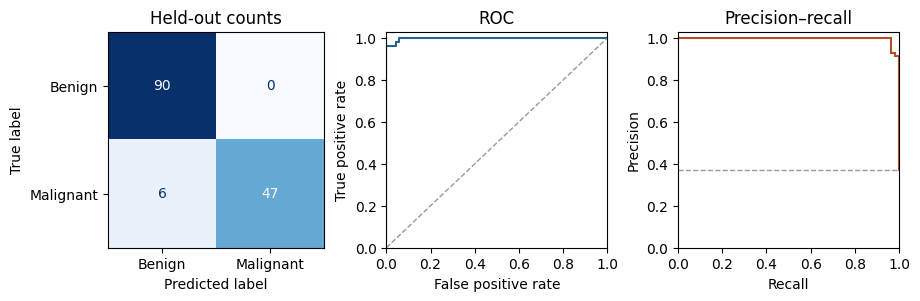

In [4]:
probability = classification_report(model, X, X_test, y, y_test)
plt.show()

## Reading the result

Minority-class covariance estimates use fewer training records. Inspect recall alongside overall accuracy.

## References

[scikit-learn, QuadraticDiscriminantAnalysis](https://scikit-learn.org/stable/modules/generated/sklearn.discriminant_analysis.QuadraticDiscriminantAnalysis.html)

[Wolberg, Mangasarian, Street and Street, Breast Cancer Wisconsin (Diagnostic), UCI, CC BY 4.0](https://doi.org/10.24432/C5DW2B)